| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../13_MODELAMIENTO_CIENTIFICO/13_1_Modelos_fisicos.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_1_Physics_Informed_Neural_Networks.ipynb) |

# 14.1 Problemas inversos: identificabilidad, ruido y regularización

**Objetivo del cuaderno.** recuperar causas desde observaciones, diagnosticar inestabilidad con SVD y calibrar parámetros con validación e incertidumbre local

**Antes de empezar:** álgebra lineal, SVD, optimización, probabilidad y modelos físicos. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)

## 1. Directo e inverso son preguntas diferentes

Un problema directo recibe parámetros o condiciones $\theta$ y calcula observaciones $y=\mathcal G(\theta)$. Un problema inverso recibe observaciones $y^{obs}$ y busca $\theta$ compatible. Ejemplos: recuperar una fuente térmica, estimar difusividad, reconstruir una imagen o encontrar una condición inicial.

El operador $\mathcal G$ puede incluir una simulación y un mapa de observación. Medir solo promedio de un campo pierde más información que observar todos sus puntos. El mismo fenómeno físico puede producir problemas inversos muy diferentes según sensores, tiempos y variables medidas.

## 2. Bien planteado y mal planteado

Un problema es bien planteado en el sentido de Hadamard si tiene solución, es única y depende continuamente de los datos en las normas consideradas. Fallar cualquiera de esas propiedades lo vuelve mal planteado.

No unicidad significa que causas distintas producen la misma observación. Inestabilidad significa que observaciones muy próximas pueden requerir causas muy distintas. Ruido y precisión numérica hacen esa inestabilidad decisiva. Una red que invierte un mapa no crea la información perdida: usa preferencias aprendidas o restricciones.

## 3. Caso lineal y SVD

En $y=A\theta+\epsilon$, la SVD $A=U\Sigma V^T$ permite escribir, cuando corresponde,

$$\theta_{LS}=\sum_j\frac{u_j^Ty}{\sigma_j}v_j.$$

Valores singulares pequeños dividen componentes del dato por números pequeños, amplificando ruido. Un valor singular cero indica una dirección no observable en el dominio. El residuo $\|A\theta-y\|$ puede ser pequeño aunque el error de reconstrucción sea enorme.

## 4. Experimento: desenfoque periódico

Construimos una matriz de suavizado gaussiano periódico sobre 80 puntos. Cada fila suma uno y difumina detalles finos. La señal verdadera contiene dos picos; la observación se obtiene al aplicar $A$ y añadir ruido conocido. La convolución suaviza información de alta frecuencia, por lo que invertirla directamente será delicado.

Condición numérica: 2.9549244227593776e+16
LS: residuo= 0.03339483093729663 error causa= 201860441983.2166


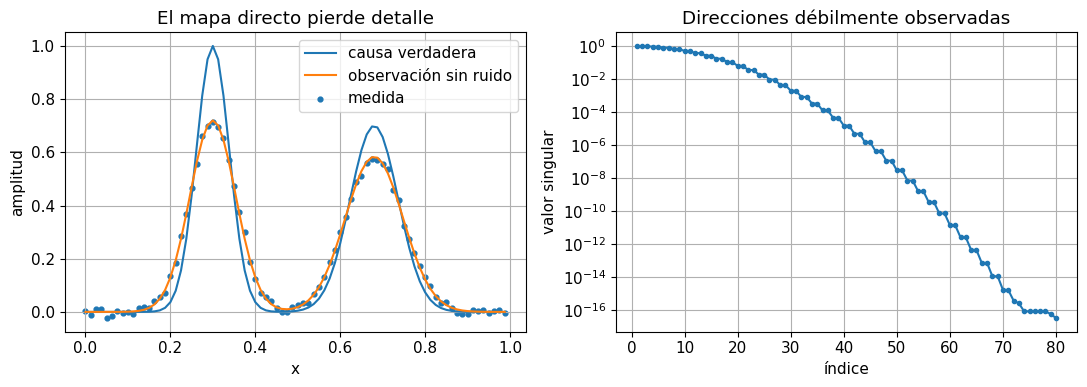

In [2]:
N=80;x=np.arange(N)/N
indices=np.arange(N)
distance=np.abs(indices[:,None]-indices[None,:]);distance=np.minimum(distance,N-distance)
A=np.exp(-0.5*(distance/3.)**2);A/=A.sum(axis=1,keepdims=True)
theta_true=np.exp(-((x-0.3)/0.055)**2)+0.7*np.exp(-((x-0.68)/0.08)**2)
clean=A@theta_true;noise_std=0.012;noise=rng.normal(0,noise_std,N);y=clean+noise
U,s,Vt=np.linalg.svd(A,full_matrices=False)
theta_ls=np.linalg.lstsq(A,y,rcond=1e-14)[0]
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(x,theta_true,label='causa verdadera');ax[0].plot(x,clean,label='observación sin ruido');ax[0].scatter(x,y,s=12,label='medida')
ax[0].set(xlabel='x',ylabel='amplitud',title='El mapa directo pierde detalle');ax[0].legend()
ax[1].semilogy(np.arange(1,N+1),s,'o-',markersize=3);ax[1].set(xlabel='índice',ylabel='valor singular',title='Direcciones débilmente observadas')
plt.tight_layout();plt.show()
print('Condición numérica:',s[0]/s[-1])
print('LS: residuo=',np.linalg.norm(A@theta_ls-y),'error causa=',np.linalg.norm(theta_ls-theta_true))

**Interpretación.** Los datos parecen suaves y bien medidos, pero los valores singulares abarcan muchas escalas. Las componentes pequeñas no soportan inversión directa con este ruido. El corte `rcond` de mínimos cuadrados elimina singularidades numéricas extremas, pero no constituye por sí solo una elección científicamente validada de regularización.

## 5. Regularización de Tikhonov

La idea es cambiar el problema hacia una solución estable y compatible con preferencias:

$$\theta_\lambda=\arg\min_\theta\{\|A\theta-y\|^2+\lambda\|L\theta\|^2\}.$$

$L=I$ favorece norma pequeña; un operador de derivadas favorece suavidad. El parámetro $\lambda>0$ controla la tensión entre ajuste y preferencia. No hay motivo para que la solución regularizada ajuste todos los datos ruidosos.

Con $L=I$ los factores de filtro son

$$\theta_\lambda=\sum_j\frac{\sigma_j}{\sigma_j^2+\lambda}(u_j^Ty)v_j.$$

En comparación con $1/\sigma_j$, los factores dejan de amplificar sin límite las direcciones débiles. Resolver mediante SVD evita formar ecuaciones normales mal condicionadas. Especificamos aquí $\lambda$, no $\lambda^2$; ambos convenios aparecen en libros.

## 6. Seleccionar $\lambda$ sin utilizar la causa verdadera

En este experimento conocemos la norma del ruido añadido. El principio de discrepancia busca un residuo cercano a ese nivel, con un pequeño margen $\tau>1$. En datos reales se necesitaría una estimación externa del ruido. El criterio usa datos y ruido, no la señal verdadera.

La selección es demostrativa: una malla de $\lambda$ puede ser demasiado gruesa y el principio depende de un modelo de ruido adecuado. Después calculamos error de reconstrucción contra la verdad exclusivamente para analizar el experimento.

λ elegido por discrepancia: 0.011671161911100682
Objetivo de residuo: 0.0867725466750059 residuo logrado: 0.08622816625745248


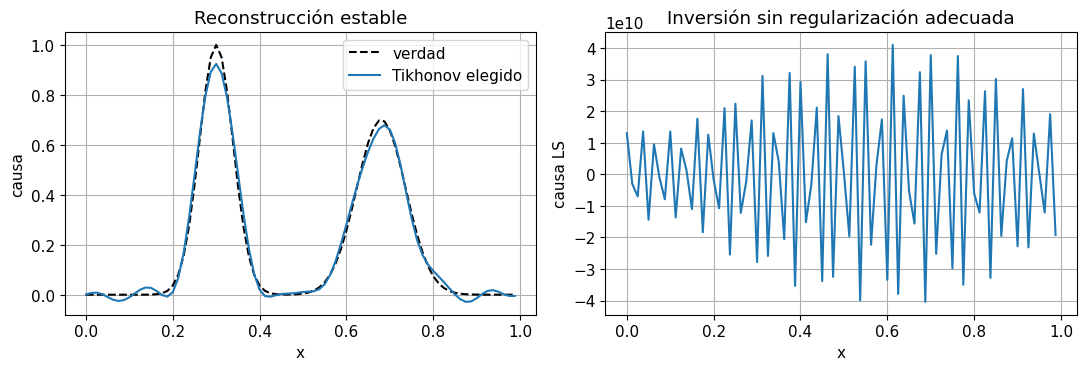

In [3]:
lambdas=np.logspace(-8,0,150)
Uy=U.T@y
reconstructions=[];residual_norms=[];solution_norms=[]
for lam in lambdas:
    estimate=Vt.T@((s/(s*s+lam))*Uy)
    reconstructions.append(estimate)
    residual_norms.append(np.linalg.norm(A@estimate-y))
    solution_norms.append(np.linalg.norm(estimate))
reconstructions=np.array(reconstructions);residual_norms=np.array(residual_norms);solution_norms=np.array(solution_norms)
discrepancy_target=1.05*np.linalg.norm(noise)
chosen_index=np.argmin(np.abs(residual_norms-discrepancy_target))
lambda_chosen=lambdas[chosen_index];theta_reg=reconstructions[chosen_index]
print('λ elegido por discrepancia:',lambda_chosen)
print('Objetivo de residuo:',discrepancy_target,'residuo logrado:',residual_norms[chosen_index])
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(x,theta_true,'k--',label='verdad');ax[0].plot(x,theta_reg,label='Tikhonov elegido')
ax[0].set(xlabel='x',ylabel='causa',title='Reconstrucción estable');ax[0].legend()
ax[1].plot(x,theta_ls);ax[1].set(xlabel='x',ylabel='causa LS',title='Inversión sin regularización adecuada')
plt.tight_layout();plt.show()

**Interpretación.** La regularización recupera estructura gruesa, pero puede suavizar picos y sesgar amplitudes. Esa pérdida de detalle es parte del compromiso para no amplificar ruido. La escala del panel de mínimos cuadrados puede ser enorme: un residuo pequeño no sirve como certificado de una causa plausible.

## 7. Curva L y error de reconstrucción

La curva L representa norma de residuo frente a norma de solución en escala logarítmica. Un cambio de curvatura puede sugerir una transición entre ajustar ruido y regularizar demasiado. No siempre existe una esquina clara ni siempre coincide con un óptimo científico.

El error contra verdad sintética permite ver dónde estaría la elección ideal en este experimento, pero sería fuga de información usar esa verdad para seleccionar en un problema real. Diferenciamos el análisis controlado de un criterio operativo.

Error regularizado: 0.20694822513572564


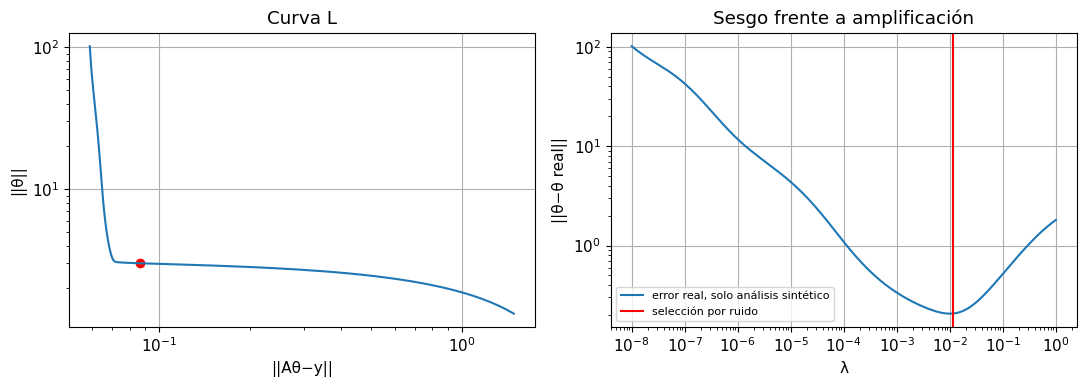

In [4]:
true_errors=np.linalg.norm(reconstructions-theta_true[None,:],axis=1)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].loglog(residual_norms,solution_norms);ax[0].scatter(residual_norms[chosen_index],solution_norms[chosen_index],c='red')
ax[0].set(xlabel='||Aθ−y||',ylabel='||θ||',title='Curva L')
ax[1].loglog(lambdas,true_errors,label='error real, solo análisis sintético')
ax[1].axvline(lambda_chosen,c='red',label='selección por ruido');ax[1].set(xlabel='λ',ylabel='||θ−θ real||',title='Sesgo frente a amplificación');ax[1].legend(fontsize=8)
plt.tight_layout();plt.show()
print('Error regularizado:',true_errors[chosen_index])
assert true_errors[chosen_index]<np.linalg.norm(theta_ls-theta_true)

## 8. Truncamiento SVD y preferencias físicas

TSVD conserva solo $r$ direcciones singulares. Es un filtro duro: $\theta_r=\sum_{j\le r}(u_j^Ty/\sigma_j)v_j$. Tikhonov es un filtro gradual. Ambos necesitan seleccionar intensidad según ruido y objetivo.

Positividad o conservación pueden añadirse como restricciones. Resolver Tikhonov y luego recortar valores negativos no resuelve en general la optimización restringida original. Para $L=I$, la formulación aumentada $[A;\sqrt\lambda I]\theta\approx[y;0]$ permite usar un solver con cotas no negativas.

## 9. Resolver con no negatividad explícita

La señal verdadera es no negativa, así que podemos incluir ese conocimiento. No lo hacemos porque lo sugiera la inversión ruidosa, sino porque forma parte del ejemplo. La solución restringida puede mejorar plausibilidad, aunque no hay garantía universal de menor error para todo ruido.

In [5]:
augmented_A=np.vstack([A,np.sqrt(lambda_chosen)*np.eye(N)])
augmented_y=np.concatenate([y,np.zeros(N)])
positive=optimize.lsq_linear(augmented_A,augmented_y,bounds=(0,np.inf),tol=1e-10)
assert positive.success
print('Mínimo componente solución positiva:',positive.x.min())
print('Error reconstrucción con positividad:',np.linalg.norm(positive.x-theta_true))
print('Error sin positividad:',np.linalg.norm(theta_reg-theta_true))
assert positive.x.min()>=0

Mínimo componente solución positiva: 2.0653389472588137e-49
Error reconstrucción con positividad: 0.18992507557545482
Error sin positividad: 0.20694822513572564


## 10. Problemas no lineales e identificabilidad local

Para $y=\mathcal G(\theta)$ no lineal, el Jacobiano $D\mathcal G$ describe sensibilidades locales. Columnas dependientes implican combinaciones difíciles de separar. La identificabilidad estructural pregunta si datos ideales determinan parámetros; la práctica considera ruido, tiempos finitos y sensores.

Un objetivo con varios mínimos o una dirección plana requiere más diagnóstico que `success=True`. Cambiar inicialización, visualizar perfiles de pérdida, examinar valores singulares y diseñar mediciones nuevas pueden ser más útiles que aumentar precisión del optimizador.

## 11. Estimar dos parámetros de un decaimiento

El modelo $u(t;a,k)=a e^{-kt}$ es directo; recuperar $a,k$ es inverso. Reservamos tiempos posteriores para evaluar predicción. El Jacobiano tiene columnas $e^{-kt}$ y $-at e^{-kt}$. Si solo medimos cerca de cero, la segunda columna es pequeña y estimar $k$ es difícil.

Estimación a,k: [1.29784 0.55882] Desviaciones locales aproximadas: [0.01149 0.00824]
Valores singulares del Jacobiano: [203.20048  75.40529]
RMSE temporal reservado: 0.024744537621564075


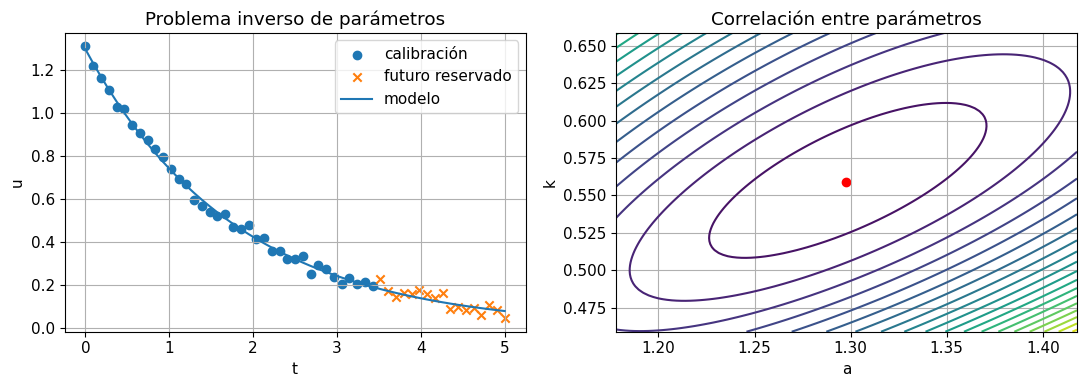

In [6]:
t=np.linspace(0,5,55);a_true=1.3;k_true=0.55;sigma=0.025
measurements=a_true*np.exp(-k_true*t)+rng.normal(0,sigma,len(t))
train=t<=3.5
def response(th,times):return th[0]*np.exp(-th[1]*times)
def residual(th):return (response(th,t[train])-measurements[train])/sigma
def jacobian(th):
    e=np.exp(-th[1]*t[train]);return np.column_stack([e,-th[0]*t[train]*e])/sigma
fit=optimize.least_squares(residual,[0.8,0.9],jac=jacobian,bounds=([0,0],[3,3]))
assert fit.success
J=jacobian(fit.x)
covariance=np.linalg.inv(J.T@J)
standard_errors=np.sqrt(np.diag(covariance))
print('Estimación a,k:',fit.x,'Desviaciones locales aproximadas:',standard_errors)
print('Valores singulares del Jacobiano:',np.linalg.svd(J,compute_uv=False))
print('RMSE temporal reservado:',np.sqrt(np.mean((response(fit.x,t[~train])-measurements[~train])**2)))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(t[train],measurements[train],label='calibración');ax[0].scatter(t[~train],measurements[~train],marker='x',label='futuro reservado')
ax[0].plot(t,response(fit.x,t),label='modelo');ax[0].set(xlabel='t',ylabel='u',title='Problema inverso de parámetros');ax[0].legend()
a_grid,k_grid=np.meshgrid(np.linspace(fit.x[0]-0.12,fit.x[0]+0.12,100),np.linspace(fit.x[1]-0.1,fit.x[1]+0.1,100))
objective=np.zeros_like(a_grid)
for ti,yi in zip(t[train],measurements[train]):objective+=(a_grid*np.exp(-k_grid*ti)-yi)**2/sigma**2
ax[1].contour(a_grid,k_grid,objective,levels=18);ax[1].scatter(*fit.x,c='red');ax[1].set(xlabel='a',ylabel='k',title='Correlación entre parámetros')
plt.tight_layout();plt.show()

**Interpretación.** Las curvas alargadas indican correlación: variar amplitud y decaimiento conjuntamente puede mantener predicciones próximas. La matriz de covarianza aproximada usa linealización local y ruido gaussiano conocido. No representa multimodalidad, errores de modelo ni incertidumbre global cerca de cotas activas.

## 12. Visión bayesiana y MAP

Bayes combina $p(\theta\mid y)\propto p(y\mid\theta)p(\theta)$. Con ruido gaussiano y prior gaussiano, maximizar posterior produce una forma de Tikhonov. Por tanto regularizar también puede interpretarse como introducir información previa, con escalas y unidades explícitas.

Un estimador MAP es un punto, no toda la distribución posterior. Una incertidumbre pequeña bajo un prior fuerte puede reflejar ese prior más que información de los datos. Revisar sensibilidad a prior y likelihood ayuda a evitar interpretaciones excesivas.

## 13. Conexión con SciML y diseño experimental

Una PINN inversa puede entrenar simultáneamente campo y coeficientes de PDE; un surrogate puede abaratar evaluaciones de $\mathcal G$; differentiable physics puede calcular gradientes de simulación. Todas estas herramientas heredan las limitaciones de observabilidad y ruido del problema.

Para aprender varios parámetros, busca sensores que produzcan sensibilidades distintas, reserva experimentos enteros y comprueba que un parámetro aprendido se mantenga al cambiar condiciones. Si solo importa predicción, puede ser aceptable una combinación de parámetros no única; si importa inferir mecanismos, esa no unicidad debe resolverse o declararse.

In [7]:
short=t<=0.3
short_J=np.column_stack([np.exp(-fit.x[1]*t[short]),-fit.x[0]*t[short]*np.exp(-fit.x[1]*t[short])])/sigma
print('Condición Jacobiano tiempos completos:',np.linalg.cond(J))
print('Condición Jacobiano tiempos muy tempranos:',np.linalg.cond(short_J))
print('Sensibilidad k en t=0:',-fit.x[0]*0*np.exp(-fit.x[1]*0))
assert np.isfinite(covariance).all()

Condición Jacobiano tiempos completos: 2.69477758301623
Condición Jacobiano tiempos muy tempranos: 7.683413639939606
Sensibilidad k en t=0: -0.0


## Síntesis y conexión con Scientific Machine Learning

Invertir observaciones exige información y estabilidad, no solo un buen optimizador. SVD diagnostica direcciones débiles; regularización controla ruido a cambio de sesgo; restricciones y priors añaden información. SciML acelera o estructura la inversión, pero debe validar identificabilidad, predicción e incertidumbre.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../13_MODELAMIENTO_CIENTIFICO/13_1_Modelos_fisicos.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_1_Physics_Informed_Neural_Networks.ipynb) |